# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

THE ABOVE LINK IS JUST FOR REFERENCE - PLEASE DO NOT USE THE DATASET PROVIDED IN THE ABOVE WEBPAGE FOR SOLVING THE ASSIGNMENT.

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [199]:
#  Import warnings
import warnings
warnings.filterwarnings('ignore')

In [3]:
%pip install numpy pandas matplotlib seaborn

In [200]:
%pip install pyarrow

In [201]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow
import os
from pathlib import Path

In [202]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 2.0.2
pandas version: 2.2.2
matplotlib version: 3.10.0
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

In [203]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [206]:
# Define constants
BASE_PATH = Path("/content/drive/MyDrive/Colab Notebooks/EDA-NY-Taxi-Assignment")
TRIP_RECORDS = 'trip_records'
YEARLY_SAMPLED_DATA = 'yearly_sampled_data.csv'

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [207]:
# Try loading one file

df = pd.read_parquet(BASE_PATH/TRIP_RECORDS/"2023-1.parquet")
df.tpep_pickup_datetime
df.info()
df

<class 'pandas.core.frame.DataFrame'>
Index: 3041714 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            floa

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.30,1.00,0.5,0.00,0.0,1.0,14.30,2.5,0.00
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.90,1.00,0.5,4.00,0.0,1.0,16.90,2.5,0.00
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.90,1.00,0.5,15.00,0.0,1.0,34.90,2.5,0.00
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.10,7.25,0.5,0.00,0.0,1.0,20.85,0.0,1.25
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.40,1.00,0.5,3.28,0.0,1.0,19.68,2.5,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3066761,2,2023-01-31 23:58:34,2023-02-01 00:12:33,NaN,3.05,NaN,None,107,48,0,15.80,0.00,0.5,3.96,0.0,1.0,23.76,NaN,NaN
3066762,2,2023-01-31 23:31:09,2023-01-31 23:50:36,NaN,5.80,NaN,None,112,75,0,22.43,0.00,0.5,2.64,0.0,1.0,29.07,NaN,NaN
3066763,2,2023-01-31 23:01:05,2023-01-31 23:25:36,NaN,4.67,NaN,None,114,239,0,17.61,0.00,0.5,5.32,0.0,1.0,26.93,NaN,NaN
3066764,2,2023-01-31 23:40:00,2023-01-31 23:53:00,NaN,3.15,NaN,None,230,79,0,18.15,0.00,0.5,4.43,0.0,1.0,26.58,NaN,NaN


How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [ ]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [10]:
# Select the folder having data files
# Create a list of all the twelve files to read
file_list = os.listdir(BASE_PATH/TRIP_RECORDS)
file_list

['2023-1.parquet',
 '2023-2.parquet',
 '2023-3.parquet',
 '2023-4.parquet',
 '2023-5.parquet',
 '2023-6.parquet',
 '2023-7.parquet',
 '2023-8.parquet',
 '2023-9.parquet',
 '2023-10.parquet',
 '2023-11.parquet',
 '2023-12.parquet']

In [208]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files

# Select the folder having data files

# Create a list of all the twelve files to read
file_list = [
    f for f in os.listdir(BASE_PATH/TRIP_RECORDS)
    if f.startswith("2023-")
    and f.endswith(".parquet")
]

print(file_list)

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file

        # Reading the current file
        df_cf = pd.read_parquet(BASE_PATH/TRIP_RECORDS/file_name)
        hourly_sample = (
        df_cf.groupby([
            df_cf["tpep_pickup_datetime"].dt.date,
            df_cf["tpep_pickup_datetime"].dt.hour
        ], group_keys=False)
        .apply(lambda x: x.sample(frac=0.05, random_state=42))
)
        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        df = pd.concat([df, hourly_sample], ignore_index=True)

        # Loop through dates and then loop through every hour of each date

            # Iterate through each hour of the selected date

                # Sample 5% of the hourly data randomly

                # add data of this hour to the dataframe

        # Concatenate the sampled data of all the dates to a single dataframe

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

['2023-1.parquet', '2023-2.parquet', '2023-3.parquet', '2023-4.parquet', '2023-5.parquet', '2023-6.parquet', '2023-7.parquet', '2023-8.parquet', '2023-9.parquet', '2023-10.parquet', '2023-11.parquet', '2023-12.parquet']


After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [209]:
# Load the new data file
def save_csv(df):
  df.to_csv(BASE_PATH/YEARLY_SAMPLED_DATA)

# def load_csv():
#   global df
#   df = pd.read_csv(BASE_PATH/YEARLY_SAMPLED_DATA)


In [210]:
# Store the df in csv/parquet
df = df.sort_values(
    by="tpep_pickup_datetime"
)
save_csv(df)

In [ ]:
 # Select the folder having data files

# # Create a list of all the twelve files to read
# file_list = [
#     f for f in os.listdir(BASE_PATH/TRIP_RECORDS)
#     if f.startswith("2023-")
#     and f.endswith(".parquet")
# ]

# # initialise an empty dataframe
# df = pd.DataFrame()


# # iterate through the list of files and sample one by one:
# for file_name in file_list:
#     try:
#         # file path for the current file
#         # Reading the current file
#         df_cf = pd.read_parquet(BASE_PATH/TRIP_RECORDS/file_name)
#         print(f"{df_cf.columns}")
#         # January 2023 has airport_fee column and other months have Airport_fee column, we'll normalize it

#     except Exception as e:
#         print(f"Error reading file {file_name}: {e}")

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [27]:
# load_csv()

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1896400 entries, 0 to 1896283
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            floa

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [17]:
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,6.5,1.0,0.5,2.00,0.00,1.0,13.50,2.5,0.00,NaN
151,2,2023-01-01 00:00:57,2023-01-01 00:15:11,1.0,9.98,1.0,N,138,97,1,38.0,6.0,0.5,5.00,0.00,1.0,51.75,0.0,1.25,NaN
72,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.0,0.5,12.00,6.55,1.0,92.55,2.5,0.00,NaN
254,2,2023-01-01 00:03:01,2023-01-01 00:10:15,1.0,1.25,1.0,N,141,236,1,9.3,1.0,0.5,0.72,0.00,1.0,15.02,2.5,0.00,NaN
211,1,2023-01-01 00:03:48,2023-01-01 00:17:51,1.0,6.00,1.0,N,137,25,1,25.4,3.5,0.5,5.47,0.00,1.0,35.87,2.5,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896220,2,2023-12-31 23:53:18,2024-01-01 00:10:03,1.0,3.08,1.0,N,50,107,1,18.4,1.0,0.5,5.00,0.00,1.0,28.40,2.5,NaN,0.0
1896221,2,2023-12-31 23:54:03,2023-12-31 23:56:18,3.0,0.44,1.0,N,164,164,2,4.4,1.0,0.5,0.00,0.00,1.0,9.40,2.5,NaN,0.0
1896362,2,2023-12-31 23:54:28,2024-01-01 00:02:11,2.0,4.26,2.0,N,260,233,1,70.0,0.0,0.5,24.28,6.94,1.0,105.22,2.5,NaN,0.0
1896336,2,2023-12-31 23:57:12,2024-01-01 00:12:53,1.0,4.11,1.0,N,48,41,1,19.8,1.0,0.5,4.96,0.00,1.0,29.76,2.5,NaN,0.0


In [211]:
# Fix the index and drop any columns that are not needed
df = df.reset_index(drop=True)
# The column is named Unnamed when created directly and named unnamed when loaded from csv, so handling case.
df = df.drop(
    columns=df.columns[
        df.columns.str.contains(r"^unnamed", case=False, na=False)
    ],
    errors="ignore"
)
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,Airport_fee
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,6.5,1.0,0.5,2.00,0.00,1.0,13.50,2.5,0.00,NaN
1,2,2023-01-01 00:00:57,2023-01-01 00:15:11,1.0,9.98,1.0,N,138,97,1,38.0,6.0,0.5,5.00,0.00,1.0,51.75,0.0,1.25,NaN
2,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.0,0.5,12.00,6.55,1.0,92.55,2.5,0.00,NaN
3,2,2023-01-01 00:03:01,2023-01-01 00:10:15,1.0,1.25,1.0,N,141,236,1,9.3,1.0,0.5,0.72,0.00,1.0,15.02,2.5,0.00,NaN
4,1,2023-01-01 00:03:48,2023-01-01 00:17:51,1.0,6.00,1.0,N,137,25,1,25.4,3.5,0.5,5.47,0.00,1.0,35.87,2.5,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896395,2,2023-12-31 23:53:18,2024-01-01 00:10:03,1.0,3.08,1.0,N,50,107,1,18.4,1.0,0.5,5.00,0.00,1.0,28.40,2.5,NaN,0.0
1896396,2,2023-12-31 23:54:03,2023-12-31 23:56:18,3.0,0.44,1.0,N,164,164,2,4.4,1.0,0.5,0.00,0.00,1.0,9.40,2.5,NaN,0.0
1896397,2,2023-12-31 23:54:28,2024-01-01 00:02:11,2.0,4.26,2.0,N,260,233,1,70.0,0.0,0.5,24.28,6.94,1.0,105.22,2.5,NaN,0.0
1896398,2,2023-12-31 23:57:12,2024-01-01 00:12:53,1.0,4.11,1.0,N,48,41,1,19.8,1.0,0.5,4.96,0.00,1.0,29.76,2.5,NaN,0.0


**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [19]:
# Combine the two airport fee columns
df.columns = df.columns.str.lower()
airport_cols = df.loc[:, df.columns == "airport_fee"]
df["airport_fee"] = airport_cols.bfill(axis=1).iloc[:, 0]
df = df.loc[:, ~df.columns.duplicated()]
df

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,6.5,1.0,0.5,2.00,0.00,1.0,13.50,2.5,0.00
1,2,2023-01-01 00:00:57,2023-01-01 00:15:11,1.0,9.98,1.0,N,138,97,1,38.0,6.0,0.5,5.00,0.00,1.0,51.75,0.0,1.25
2,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.0,0.5,12.00,6.55,1.0,92.55,2.5,0.00
3,2,2023-01-01 00:03:01,2023-01-01 00:10:15,1.0,1.25,1.0,N,141,236,1,9.3,1.0,0.5,0.72,0.00,1.0,15.02,2.5,0.00
4,1,2023-01-01 00:03:48,2023-01-01 00:17:51,1.0,6.00,1.0,N,137,25,1,25.4,3.5,0.5,5.47,0.00,1.0,35.87,2.5,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896395,2,2023-12-31 23:53:18,2024-01-01 00:10:03,1.0,3.08,1.0,N,50,107,1,18.4,1.0,0.5,5.00,0.00,1.0,28.40,2.5,0.00
1896396,2,2023-12-31 23:54:03,2023-12-31 23:56:18,3.0,0.44,1.0,N,164,164,2,4.4,1.0,0.5,0.00,0.00,1.0,9.40,2.5,0.00
1896397,2,2023-12-31 23:54:28,2024-01-01 00:02:11,2.0,4.26,2.0,N,260,233,1,70.0,0.0,0.5,24.28,6.94,1.0,105.22,2.5,0.00
1896398,2,2023-12-31 23:57:12,2024-01-01 00:12:53,1.0,4.11,1.0,N,48,41,1,19.8,1.0,0.5,4.96,0.00,1.0,29.76,2.5,0.00


**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [212]:
monetary_cols = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "airport_fee"
]

negative_df = df[
    (df[monetary_cols] < 0).any(axis=1)
]

negative_df.shape

(79, 20)

In [21]:
negative_df.head(20)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
3961,2,2023-01-02 05:12:19,2023-01-02 05:41:45,1.0,17.07,3.0,N,142,1,2,0.0,0.0,0.0,0.0,0.0,-1.0,-1.00,0.0,0.00
9101,2,2023-01-03 14:24:45,2023-01-03 14:25:14,1.0,0.00,2.0,N,132,132,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-5.25,-2.5,-1.25
77109,2,2023-01-17 12:37:35,2023-01-17 13:24:00,1.0,17.68,2.0,N,230,132,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
77853,2,2023-01-17 15:03:44,2023-01-17 15:36:28,1.0,4.12,1.0,N,239,168,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
86687,2,2023-01-19 09:50:26,2023-01-19 09:58:13,1.0,0.50,1.0,N,161,43,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
117666,2,2023-01-25 11:10:37,2023-01-25 11:11:02,1.0,0.02,2.0,N,170,233,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
120259,2,2023-01-25 18:52:24,2023-01-25 19:06:34,1.0,1.75,1.0,N,140,163,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
157990,2,2023-02-02 08:12:32,2023-02-02 08:24:59,1.0,2.12,1.0,N,236,161,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
220192,2,2023-02-14 09:49:00,2023-02-14 10:01:58,1.0,2.48,1.0,N,236,263,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00
225988,2,2023-02-15 10:55:02,2023-02-15 11:56:22,1.0,12.34,1.0,N,138,230,2,0.0,0.0,-0.5,0.0,0.0,-1.0,-5.25,-2.5,-1.25


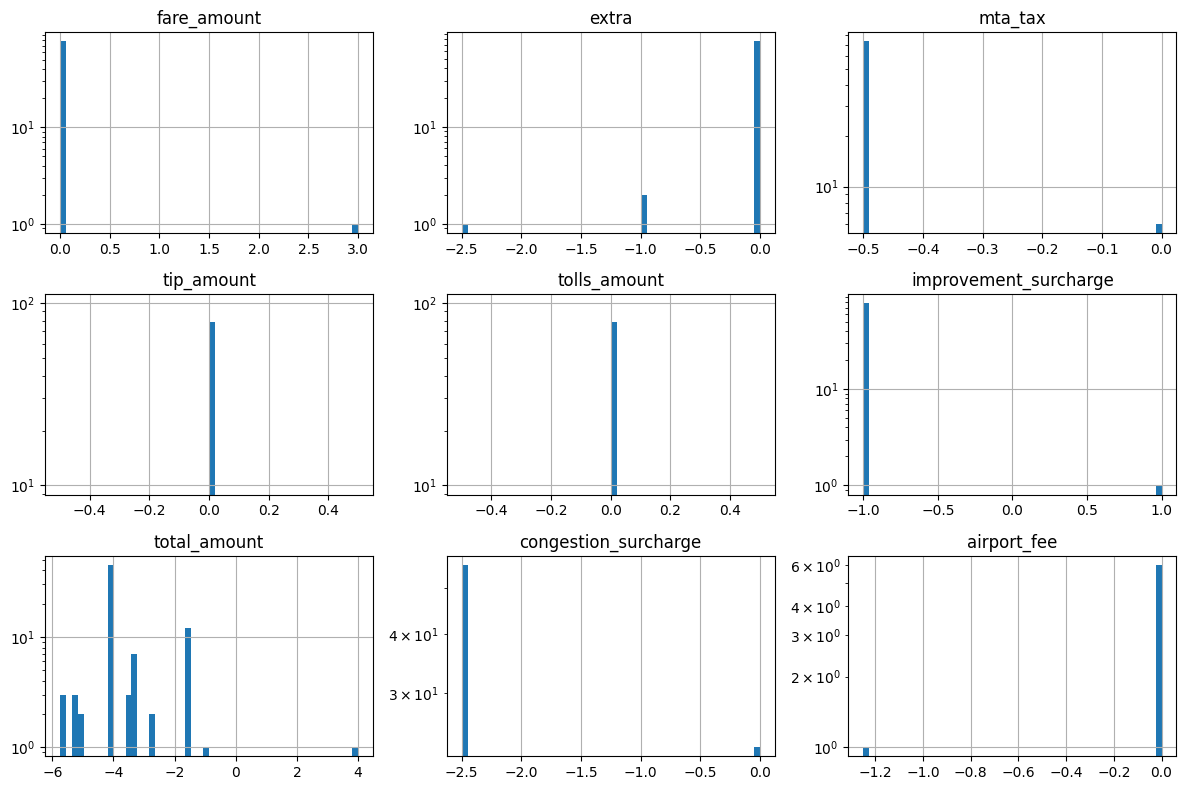

In [215]:

negative_df[monetary_cols].hist(
    figsize=(12, 8),
    bins=50,
    log= True
)

plt.tight_layout()
plt.show()

Did you notice something different in the `RatecodeID` column for above records?

In [26]:
# Analyse RatecodeID for the negative fare amounts
negative_df['ratecodeid'].value_counts().sort_index()


,count
ratecodeid,
1.0,50
2.0,24
3.0,1
4.0,1
5.0,3


In [31]:
# Find which columns have negative values
negative_counts = (
    df.select_dtypes(include="number") < 0
).sum()
negative_counts[negative_counts > 0]

,0
extra,1


In [22]:
# fix these negative values
df = df[
    (df["fare_amount"] >= 0) &
    (df["total_amount"] >= 0)
].copy()


In [23]:
df.shape

(1896322, 19)

### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [24]:
# missing all data
df.isnull().sum().sum()

np.int64(324370)

In [25]:
# Find the proportion of missing values in each column
df.isnull().sum()


,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,64874
trip_distance,0
ratecodeid,64874
store_and_fwd_flag,64874
pulocationid,0
dolocationid,0
payment_type,0


In [33]:
datetime_cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime"
]

for col in datetime_cols:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce"
    )

**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [34]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'
df[df['passenger_count'].isna()]


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
28,2,2023-01-01 00:09:36,2023-01-01 00:21:45,NaN,2.34,NaN,None,140,239,0,16.38,0.0,0.5,2.04,0.0,1.0,22.42,NaN,NaN
56,2,2023-01-01 00:16:00,2023-01-01 00:38:00,NaN,4.77,NaN,None,90,262,0,27.42,0.0,0.5,7.86,0.0,1.0,39.28,NaN,NaN
67,2,2023-01-01 00:17:00,2023-01-01 00:46:00,NaN,5.89,NaN,None,144,262,0,28.19,0.0,0.5,3.22,0.0,1.0,35.41,NaN,NaN
119,1,2023-01-01 00:28:22,2023-01-01 00:41:25,NaN,2.90,NaN,None,263,137,0,15.60,1.0,0.5,3.09,0.0,1.0,23.69,NaN,NaN
152,1,2023-01-01 00:37:09,2023-01-01 00:58:16,NaN,0.00,NaN,None,36,7,0,27.50,1.0,0.5,0.00,0.0,1.0,32.00,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896331,2,2023-12-31 23:29:32,2023-12-31 23:45:51,NaN,7.47,NaN,None,41,4,0,29.05,0.0,0.5,0.00,0.0,1.0,33.05,NaN,NaN
1896332,1,2023-12-31 23:29:57,2023-12-31 23:51:06,NaN,0.00,NaN,None,43,244,0,27.74,0.0,0.5,0.00,0.0,1.0,31.74,NaN,NaN
1896355,2,2023-12-31 23:35:59,2023-12-31 23:39:21,NaN,0.76,NaN,None,141,140,0,6.83,0.0,0.5,0.00,0.0,1.0,10.83,NaN,NaN
1896364,2,2023-12-31 23:38:22,2024-01-01 00:02:48,NaN,8.38,NaN,None,244,137,0,34.93,0.0,0.5,0.00,0.0,1.0,38.93,NaN,NaN


In [35]:
df["passenger_count"].value_counts(dropna=False).sort_index()

,count
passenger_count,
0.0,29681
1.0,1377169
2.0,277283
3.0,69032
4.0,38532
5.0,23871
6.0,15859
7.0,5
8.0,11


In [36]:
df["passenger_count"].median()
passenger_count_mode = df["passenger_count"].mode()[0]
missing_pct = (
    df["passenger_count"].isna().sum()
    / len(df)
    * 100
)

print(missing_pct)

3.4210434725748056


In [37]:
df['passenger_count'] = (df['passenger_count'].fillna(passenger_count_mode))

In [39]:
df["passenger_count"].value_counts(dropna=False).sort_index()

,count
passenger_count,
0.0,29681
1.0,1442043
2.0,277283
3.0,69032
4.0,38532
5.0,23871
6.0,15859
7.0,5
8.0,11


In [40]:
# Handle zeros
zero_count = (df["passenger_count"] == 0).sum()

print(zero_count)
print(round(zero_count / len(df) * 100, 2))

29681
1.57


In [41]:
df[
    df["passenger_count"] == 0
].sample(20, random_state=42)

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
481394,1,2023-04-04 08:44:45,2023-04-04 09:03:25,0.0,4.7,1.0,N,107,88,1,26.1,2.50,0.5,4.00,0.0,1.0,34.10,2.5,0.00
1555784,1,2023-10-30 10:29:33,2023-10-30 10:32:55,0.0,0.5,1.0,N,141,237,3,5.8,2.50,0.5,0.00,0.0,1.0,9.80,2.5,0.00
729522,1,2023-05-18 13:43:51,2023-05-18 13:52:09,0.0,0.7,1.0,N,234,170,1,9.3,2.50,0.5,2.65,0.0,1.0,15.95,2.5,0.00
1768572,1,2023-12-07 17:02:13,2023-12-07 17:36:11,0.0,3.1,1.0,N,48,79,1,28.2,5.00,0.5,2.00,0.0,1.0,36.70,2.5,0.00
709637,1,2023-05-15 09:08:57,2023-05-15 09:32:34,0.0,3.0,1.0,N,186,148,1,21.9,2.50,0.5,5.15,0.0,1.0,31.05,2.5,0.00
478367,1,2023-04-03 15:13:23,2023-04-03 15:21:48,0.0,0.7,1.0,N,43,237,1,9.3,2.50,0.5,2.65,0.0,1.0,15.95,2.5,0.00
1451836,1,2023-10-12 13:21:31,2023-10-12 13:25:52,0.0,0.4,1.0,N,164,230,2,5.8,2.50,0.5,0.00,0.0,1.0,9.80,2.5,0.00
391842,1,2023-03-18 08:02:46,2023-03-18 08:08:28,0.0,1.2,1.0,N,48,142,1,7.9,2.50,0.5,2.95,0.0,1.0,14.85,2.5,0.00
286712,1,2023-02-26 22:11:26,2023-02-26 22:25:44,0.0,3.7,1.0,N,142,113,1,18.4,3.50,0.5,2.50,0.0,1.0,25.90,2.5,0.00
1023274,1,2023-07-14 12:33:28,2023-07-14 12:41:39,0.0,1.1,1.0,N,170,137,2,8.6,2.50,0.5,0.00,0.0,1.0,12.60,2.5,0.00


In [42]:
zero_passenger_df = df[
    df["passenger_count"] == 0
]
zero_by_ratecode = (
    zero_passenger_df
    .groupby("ratecodeid")
    .size()
    .sort_values(ascending=False)
)

zero_by_ratecode

,0
ratecodeid,
1.0,28531
2.0,781
5.0,221
3.0,80
99.0,35
4.0,33


In [43]:
zero_by_vendorcode = (
    zero_passenger_df
    .groupby("vendorid")
    .size()
    .sort_values(ascending=False)
)

zero_by_vendorcode

,0
vendorid,
1,29586
2,95


In [46]:

df["passenger_count"] = (
    df["passenger_count"]
    .replace(0, df["passenger_count"].mode()[0])
)

In [47]:
df[df["passenger_count"] == 0][
    ["trip_distance", "fare_amount", "total_amount"]
].describe()

,trip_distance,fare_amount,total_amount
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


Did you find zeroes in passenger_count? Handle these.

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [48]:
# Fix missing values in 'RatecodeID'
print(df["ratecodeid"].value_counts(dropna=False).sort_index())
df["ratecodeid"].mode()


ratecodeid
1.0     1729210
2.0       71646
3.0        6123
4.0        3722
5.0       10272
6.0           3
99.0      10472
NaN       64874
Name: count, dtype: int64


,ratecodeid
0,1.0


In [49]:
ratecode_mode = df["ratecodeid"].mode()[0]

df["ratecodeid"] = (
    df["ratecodeid"]
    .fillna(ratecode_mode)
)

In [ ]:
# save_csv()

**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [50]:
# handle null values in congestion_surcharge
df["congestion_surcharge"].value_counts(dropna=False)
# df[
#     df["congestion_surcharge"] == 0.5
# ]


,count
congestion_surcharge,
2.5,1690572
0.0,140875
NaN,64874
0.5,1


In [51]:
pd.crosstab(
    df["airport_fee"],
    df["congestion_surcharge"]
)

congestion_surcharge,0.0,0.5,2.5
airport_fee,,,
0.00,69938,1,1600562
1.00,1,0,0
1.25,18016,0,21807
1.75,52920,0,68203


In [52]:
df.loc[
    df["congestion_surcharge"] == 0.5,
    "congestion_surcharge"
] = 0.0

df["congestion_surcharge"] = (
    df["congestion_surcharge"]
    .fillna(0)
)

Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [53]:
# Handle any remaining missing values
df.isna().sum()


,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,64874
pulocationid,0
dolocationid,0
payment_type,0


In [54]:
# How to handle store-and-flag
df["store_and_fwd_flag"].value_counts(dropna=False)

,count
store_and_fwd_flag,
N,1820209
None,64874
Y,11239


In [55]:
store_mode = df["store_and_fwd_flag"].mode()[0]

df["store_and_fwd_flag"] = (
    df["store_and_fwd_flag"]
    .fillna(store_mode)
)

In [56]:
# Now we handle airport fee
df["airport_fee"].value_counts(dropna=False)

,count
airport_fee,
0.00,1670501
1.75,121123
NaN,64874
1.25,39823
1.00,1


In [57]:
df["airport_fee"] = (
    df["airport_fee"]
    .fillna(0)
)

In [58]:
df.isna().sum()

,0
vendorid,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
ratecodeid,0
store_and_fwd_flag,0
pulocationid,0
dolocationid,0
payment_type,0


In [59]:
save_csv(df)

### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [60]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
numeric_cols = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "airport_fee",
    "congestion_surcharge"
]



In [61]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
passenger_count,1896322.0,1.372231,0.864399,1.0,1.00,1.00,1.00,9.00
trip_distance,1896322.0,3.858256,129.411168,0.0,1.05,1.80,3.40,126360.46
fare_amount,1896322.0,19.920170,105.539177,0.0,9.30,13.50,21.90,143163.45
tip_amount,1896322.0,3.547156,4.054902,0.0,1.00,2.85,4.42,223.08
tolls_amount,1896322.0,0.596558,2.187919,0.0,0.00,0.00,0.00,143.00
total_amount,1896322.0,28.983203,106.418213,0.0,15.96,21.00,30.94,143167.45
airport_fee,1896322.0,0.138028,0.457571,0.0,0.00,0.00,0.00,1.75
congestion_surcharge,1896322.0,2.228751,0.777526,0.0,2.50,2.50,2.50,2.50


In [62]:
df.nlargest(
    20,
    "trip_distance"
)[
    [
        "trip_distance",
        "fare_amount",
        "total_amount",
        "vendorid"
    ]
]

,trip_distance,fare_amount,total_amount,vendorid
789067,126360.46,85.52,114.28,2
1190520,56823.80,18.50,20.00,1
1785196,35482.69,25.91,34.40,2
1390331,34804.51,14.45,22.14,2
1788754,33133.96,12.02,18.42,2
1051220,32053.26,36.90,49.08,2
1015282,30430.04,23.01,27.01,2
776876,27586.37,46.43,56.98,2
815105,26217.98,10.63,17.56,2
1297069,22910.92,27.66,37.99,2


In [63]:
df["trip_distance"].quantile(
    [0.90, 0.95, 0.99, 0.999, 0.9999]
)

,trip_distance
0.9000,9.110000
0.9500,15.290000
0.9900,20.220000
0.9990,29.500000
0.9999,56.888296


In [64]:
df[
    df["trip_distance"] > 100
][
    [
        "trip_distance",
        "fare_amount",
        "total_amount",
        "passenger_count"
    ]
].sort_values(
    by="trip_distance",
    ascending=False
)

,trip_distance,fare_amount,total_amount,passenger_count
789067,126360.46,85.52,114.28,1.0
1190520,56823.80,18.50,20.00,1.0
1785196,35482.69,25.91,34.40,1.0
1390331,34804.51,14.45,22.14,1.0
1788754,33133.96,12.02,18.42,1.0
...,...,...,...,...
987371,107.00,728.90,762.45,2.0
1279347,105.00,500.00,535.75,1.0
1220846,104.30,23.30,30.03,1.0
1745655,101.90,372.60,381.04,1.0


In [ ]:
(df["trip_distance"] > 100).sum()

np.int64(63)

In [ ]:
df[df["trip_distance"] > 100]

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
30180,2,2023-01-07 20:02:05,2023-01-07 20:07:10,1.0,721.26,1.0,N,145,7,1,7.90,0.0,0.5,2.00,0.00,1.0,11.40,0.0,0.00
85704,1,2023-01-19 00:20:12,2023-01-19 03:38:58,1.0,204.10,5.0,N,70,265,2,600.00,0.0,0.0,0.00,6.55,1.0,607.55,0.0,0.00
92827,2,2023-01-20 11:56:36,2023-01-20 15:04:22,1.0,159.85,5.0,N,138,265,2,300.00,5.0,0.0,0.00,6.55,1.0,313.80,0.0,1.25
111421,2,2023-01-24 06:27:00,2023-01-24 07:18:00,1.0,3253.99,1.0,N,230,90,0,19.24,0.0,0.5,4.51,0.00,0.3,27.05,0.0,0.00
136770,2,2023-01-28 18:16:37,2023-01-28 18:41:22,1.0,2003.03,1.0,N,48,113,0,18.87,0.0,0.5,3.00,0.00,1.0,25.87,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1785196,2,2023-12-10 01:11:00,2023-12-10 01:25:00,1.0,35482.69,1.0,N,224,33,0,25.91,0.0,0.5,4.49,0.00,1.0,34.40,0.0,0.00
1788755,2,2023-12-10 17:10:00,2023-12-10 17:12:00,1.0,33133.96,1.0,N,142,142,0,12.02,0.0,0.5,2.40,0.00,1.0,18.42,0.0,0.00
1836238,2,2023-12-18 10:52:49,2023-12-18 13:40:43,1.0,187.35,5.0,N,246,265,1,180.00,0.0,0.0,0.15,12.75,1.0,193.90,0.0,0.00
1876332,1,2023-12-27 06:00:00,2023-12-27 07:22:13,1.0,969.10,99.0,N,258,265,1,25.50,0.0,0.5,0.00,0.00,1.0,27.00,0.0,0.00


**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [65]:
# remove passenger_count > 6
df = df[
    df["passenger_count"] <= 6
].copy()

df.reset_index(drop=True, inplace=True)

In [66]:
# Continue with outlier handling
near_zero_high_fare = df[
    (df["trip_distance"] < 0.1) &
    (df["fare_amount"] > 300)
]

near_zero_high_fare.shape


(35, 19)

In [68]:
df = df[
    ~(
        (df["trip_distance"] < 0.1) &
        (df["fare_amount"] > 300)
    )
].copy()
df

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,6.5,1.0,0.5,2.00,0.00,1.0,13.50,2.5,0.00
1,2,2023-01-01 00:00:57,2023-01-01 00:15:11,1.0,9.98,1.0,N,138,97,1,38.0,6.0,0.5,5.00,0.00,1.0,51.75,0.0,1.25
2,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,70.0,0.0,0.5,12.00,6.55,1.0,92.55,2.5,0.00
3,2,2023-01-01 00:03:01,2023-01-01 00:10:15,1.0,1.25,1.0,N,141,236,1,9.3,1.0,0.5,0.72,0.00,1.0,15.02,2.5,0.00
4,1,2023-01-01 00:03:48,2023-01-01 00:17:51,1.0,6.00,1.0,N,137,25,1,25.4,3.5,0.5,5.47,0.00,1.0,35.87,2.5,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896296,2,2023-12-31 23:53:18,2024-01-01 00:10:03,1.0,3.08,1.0,N,50,107,1,18.4,1.0,0.5,5.00,0.00,1.0,28.40,2.5,0.00
1896297,2,2023-12-31 23:54:03,2023-12-31 23:56:18,3.0,0.44,1.0,N,164,164,2,4.4,1.0,0.5,0.00,0.00,1.0,9.40,2.5,0.00
1896298,2,2023-12-31 23:54:28,2024-01-01 00:02:11,2.0,4.26,2.0,N,260,233,1,70.0,0.0,0.5,24.28,6.94,1.0,105.22,2.5,0.00
1896299,2,2023-12-31 23:57:12,2024-01-01 00:12:53,1.0,4.11,1.0,N,48,41,1,19.8,1.0,0.5,4.96,0.00,1.0,29.76,2.5,0.00


In [95]:
# Handle incorrect distance and fare as 0
zero_trip_different_zone = df[
    (df["trip_distance"] == 0) &
    (df["fare_amount"] == 0) &
    (df["pulocationid"] != df["dolocationid"])
]

df = df[
    df["fare_amount"] <= 1000
].copy()

df.reset_index(
    drop=True,
    inplace=True
)

zero_trip_different_zone.shape

(0, 22)

In [70]:
df = df[
    ~(
        (df["trip_distance"] == 0) &
        (df["fare_amount"] == 0) &
        (df["pulocationid"] != df["dolocationid"])
    )
].copy()

In [71]:
long_trip_df = df[
    df["trip_distance"] > 250
]

long_trip_df.shape

(46, 19)

In [72]:
df = df[
    df["trip_distance"] <= 250
].copy()

In [75]:
df["payment_type"].value_counts().sort_index()

,count
payment_type,
0,64844
1,1492299
2,316343
3,9006
4,13669


In [77]:
df = df[
    df["payment_type"] != 0
].copy()

In [ ]:
# Do any columns need standardising?
# we have standarize date column already


In [79]:
save_csv(df)

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [78]:
df.columns.tolist()

['vendorid',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'ratecodeid',
 'store_and_fwd_flag',
 'pulocationid',
 'dolocationid',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`:
* `tpep_pickup_datetime`:
* `tpep_dropoff_datetime`:
* `passenger_count`:
* `trip_distance`:
* `RatecodeID`:
* `PULocationID`:
* `DOLocationID`:
* `payment_type`:
* `pickup_hour`:
* `trip_duration`:


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

In [80]:
# Find and show the hourly trends in taxi pickups
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour


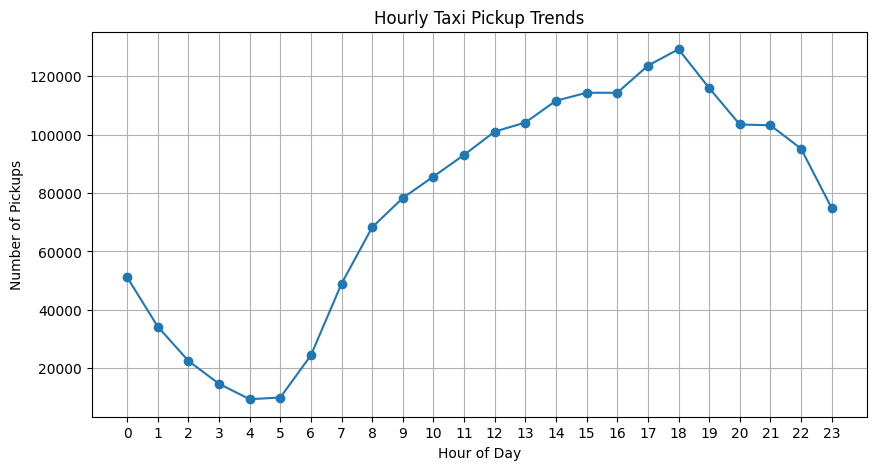

In [97]:
# Find and show the daily trends in taxi pickups (days of the week)
hourly_pickups = (
    df.groupby("pickup_hour")
      .size()
      .reset_index(name="trip_count")
)

hourly_pickups
plt.figure(figsize=(10, 5))
plt.plot(
    hourly_pickups["pickup_hour"],
    hourly_pickups["trip_count"],
    marker="o"
)

plt.xticks(range(24))
plt.xlabel("Hour of Day")
plt.ylabel("Number of Pickups")
plt.title("Hourly Taxi Pickup Trends")
plt.grid(True)

plt.show()

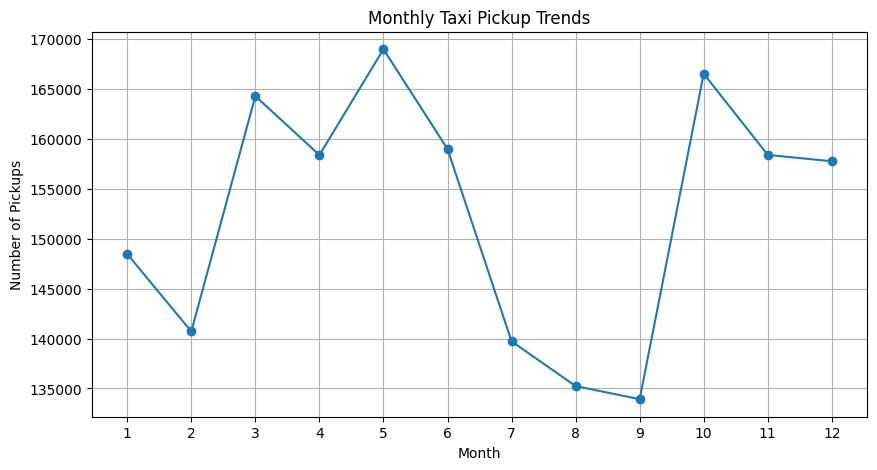

In [98]:
# Show the monthly trends in pickups
df["pickup_month"] = (
    df["tpep_pickup_datetime"]
      .dt.month
)
monthly_pickups = (
    df.groupby("pickup_month")
      .size()
      .reset_index(name="trip_count")
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pickups["pickup_month"],
    monthly_pickups["trip_count"],
    marker="o"
)

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Number of Pickups")
plt.title("Monthly Taxi Pickup Trends")
plt.grid(True)

plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [ ]:
# Analyse the above parameters

# We have already cleaned the data

Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [88]:
df_non_zeros = df[
    (df["trip_distance"] > 0) &
    (df["fare_amount"] > 0) &
    (df["tip_amount"] > 0) &
    (df["total_amount"] > 0)
]
df_non_zeros

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_hour,pickup_month
0,2,2022-12-31 23:51:30,2022-12-31 23:56:06,1.0,0.86,1.0,N,141,140,1,...,1.0,0.5,2.00,0.00,1.0,13.50,2.5,0.00,23,12
1,2,2023-01-01 00:00:57,2023-01-01 00:15:11,1.0,9.98,1.0,N,138,97,1,...,6.0,0.5,5.00,0.00,1.0,51.75,0.0,1.25,0,1
2,2,2023-01-01 00:02:19,2023-01-01 00:30:49,1.0,20.37,2.0,N,132,140,1,...,0.0,0.5,12.00,6.55,1.0,92.55,2.5,0.00,0,1
3,2,2023-01-01 00:03:01,2023-01-01 00:10:15,1.0,1.25,1.0,N,141,236,1,...,1.0,0.5,0.72,0.00,1.0,15.02,2.5,0.00,0,1
4,1,2023-01-01 00:03:48,2023-01-01 00:17:51,1.0,6.00,1.0,N,137,25,1,...,3.5,0.5,5.47,0.00,1.0,35.87,2.5,0.00,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1896293,2,2023-12-31 23:49:30,2023-12-31 23:58:10,2.0,1.35,1.0,N,48,239,1,...,1.0,0.5,3.00,0.00,1.0,18.00,2.5,0.00,23,12
1896295,2,2023-12-31 23:52:29,2024-01-01 00:02:11,1.0,4.24,1.0,N,132,139,1,...,1.0,0.5,4.82,0.00,1.0,30.67,2.5,1.75,23,12
1896296,2,2023-12-31 23:53:18,2024-01-01 00:10:03,1.0,3.08,1.0,N,50,107,1,...,1.0,0.5,5.00,0.00,1.0,28.40,2.5,0.00,23,12
1896298,2,2023-12-31 23:54:28,2024-01-01 00:02:11,2.0,4.26,2.0,N,260,233,1,...,0.0,0.5,24.28,6.94,1.0,105.22,2.5,0.00,23,12



**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

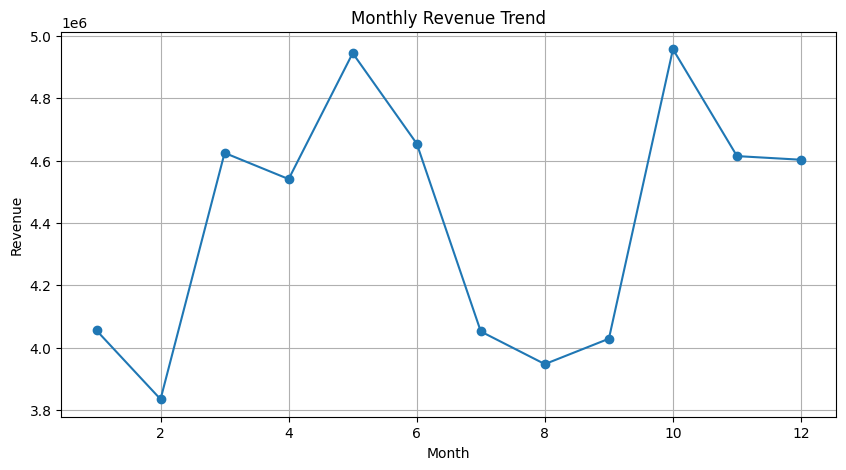

In [99]:
# Group data by month and analyse monthly revenue
monthly_revenue = (
    df.groupby("pickup_month")["total_amount"]
      .sum()
      .reset_index()
)

monthly_revenue

plt.figure(figsize=(10,5))

plt.plot(
    monthly_revenue["pickup_month"],
    monthly_revenue["total_amount"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")

plt.grid(True)

plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

<Axes: ylabel='total_amount'>

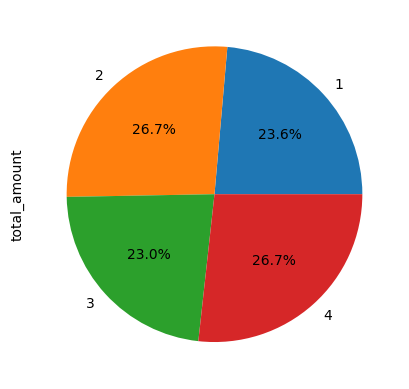

In [91]:
# Calculate proportion of each quarter
df["quarter"] = (
    df["tpep_pickup_datetime"]
      .dt.quarter
)

quarterly_revenue = (
    df.groupby("quarter")["total_amount"]
      .sum()
)

quarterly_pct = (
    quarterly_revenue
    / quarterly_revenue.sum()
    * 100
)

quarterly_pct.plot(
    kind="pie",
    autopct="%1.1f%%"
)


**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

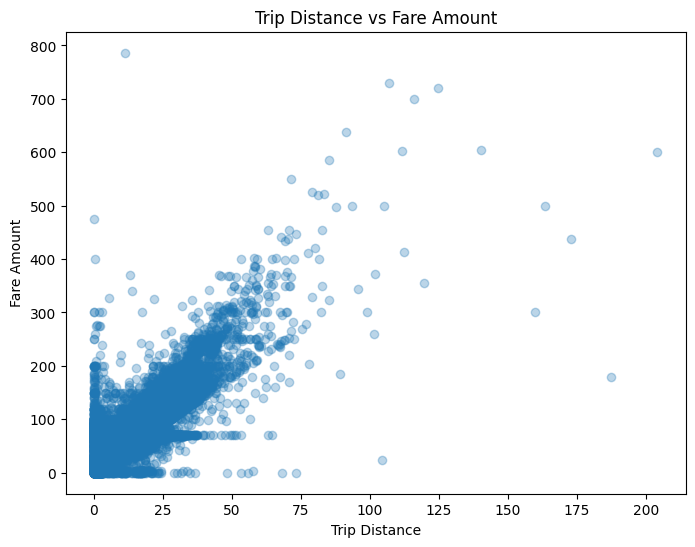

In [102]:
# Show how trip fare is affected by distance
distance_fare_df = df[
    df["trip_distance"] > 0
]

distance_fare_df[
    ["trip_distance", "fare_amount"]
].corr()

plt.figure(figsize=(8,6))

plt.scatter(
    distance_fare_df["trip_distance"],
    distance_fare_df["fare_amount"],
    alpha=0.3
)

plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.title("Trip Distance vs Fare Amount")

plt.show()

In [94]:
df[
    df["fare_amount"] > 10000
]

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_hour,pickup_month,quarter
1266210,1,2023-09-05 10:16:13,2023-09-05 10:20:56,1.0,0.7,1.0,N,249,90,2,...,0.5,0.0,0.0,1.0,143167.45,2.5,0.0,10,9,3


**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

In [103]:
# Show relationship between fare and trip duration
df["trip_duration"] = (
    df["tpep_dropoff_datetime"] -
    df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["trip_duration"].describe()


,trip_duration
count,1.831315e+06
mean,1.736630e+01
std,4.171434e+01
min,-5.430000e+01
25%,7.583333e+00
50%,1.253333e+01
75%,2.050000e+01
max,6.266383e+03


In [105]:
negative_duration_df = df[
    df["trip_duration"] < 0
]

negative_duration_df.shape

(43, 23)

In [106]:
negative_duration_df[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_duration",
        "trip_distance",
        "fare_amount"
    ]
].head(20)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration,trip_distance,fare_amount
155514,2023-02-02 13:02:23,2023-02-02 12:50:35,-11.800000,1.00,43.5
1067974,2023-07-29 11:45:00,2023-07-29 11:29:01,-15.983333,3.60,24.5
1198894,2023-08-28 12:28:00,2023-08-28 12:17:18,-10.700000,3.30,25.5
1211566,2023-08-31 11:40:00,2023-08-31 11:24:26,-15.566667,1.80,19.5
1539385,2023-11-05 01:22:28,2023-11-05 01:10:25,-12.050000,9.88,54.1
1539403,2023-11-05 01:24:15,2023-11-05 01:03:15,-21.000000,7.76,42.2
1539405,2023-11-05 01:24:41,2023-11-05 01:00:00,-24.683333,6.84,38.0
1539411,2023-11-05 01:25:30,2023-11-05 01:08:04,-17.433333,9.01,46.4
1539479,2023-11-05 01:36:34,2023-11-05 01:09:50,-26.733333,5.10,33.1
1539503,2023-11-05 01:40:43,2023-11-05 01:06:12,-34.516667,3.75,23.3


In [107]:
(df["trip_duration"] < 0).sum()

np.int64(43)

In [109]:
# Trip duraition more thatn 5 hrs
df[
    df["trip_duration"] > 300
][
    [
        "trip_duration",
        "trip_distance",
        "fare_amount"
    ]
].sort_values(
    "trip_duration",
    ascending=False
).head(20)

,trip_duration,trip_distance,fare_amount
1333074,6266.383333,0.00,3.00
1254905,5522.433333,0.49,8.60
1759992,5411.000000,0.50,17.70
1417157,5329.433333,13.40,55.50
358056,5125.216667,0.00,3.00
1375576,5016.233333,7.76,70.00
27246,3040.516667,1.86,12.80
1683869,2658.850000,7.99,42.90
1458211,2608.416667,19.87,70.00
425007,2510.316667,0.00,3.00


In [110]:
df = df[
    (df["trip_duration"] > 0) &
    (df["trip_duration"] <= 300)
].copy()

df.reset_index(drop=True, inplace=True)

In [111]:
save_csv(df)

In [112]:
corr = df["fare_amount"].corr(
    df["trip_duration"]
)

print(corr)

0.8097963063824168


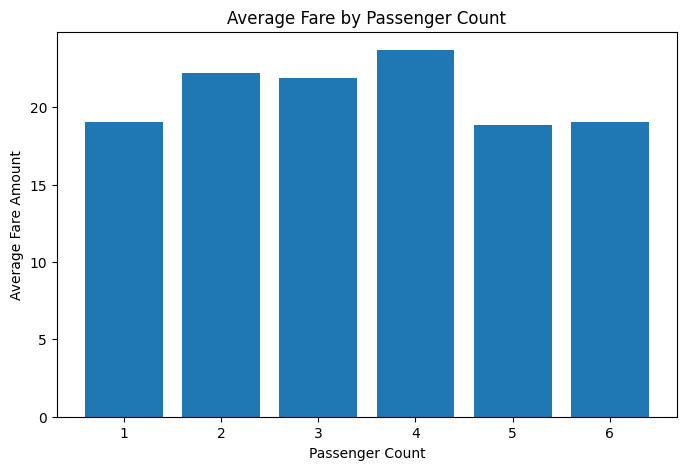

In [113]:
# Show relationship between fare and number of passengers

fare_by_passenger = (
    df.groupby("passenger_count")["fare_amount"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    fare_by_passenger["passenger_count"],
    fare_by_passenger["fare_amount"]
)

plt.xlabel("Passenger Count")
plt.ylabel("Average Fare Amount")
plt.title("Average Fare by Passenger Count")

plt.show()

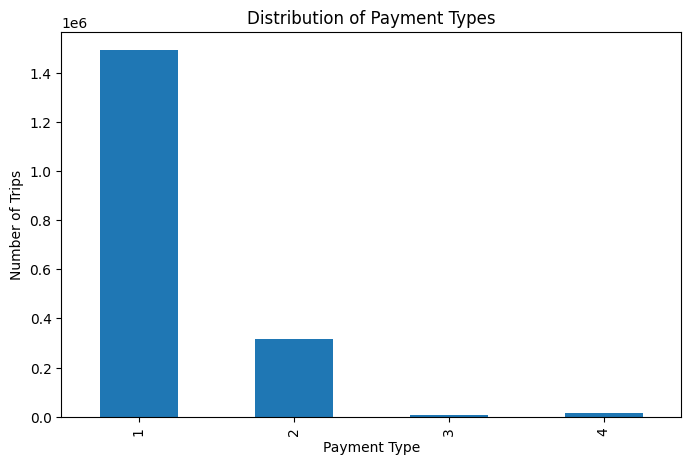

In [117]:
# Show relationship between tip and trip distance
tip_distance_corr = df["tip_amount"].corr(
    df["trip_distance"]
)

payment_pct = (
    df["payment_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .sort_index()
)

payment_pct

payment_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Payment Type")
plt.ylabel("Number of Trips")
plt.title("Distribution of Payment Types")

plt.show()


**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

In [115]:
# Analyse the distribution of different payment types (payment_type).
payment_counts = (
    df["payment_type"]
    .value_counts()
    .sort_index()
)

payment_counts




,count
payment_type,
1,1491053
2,315340
3,8988
4,13665


- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute



##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [118]:
!pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [127]:
import geopandas as gpd

# Read the shapefile using geopandas
zones = gpd.read_file(
    BASE_PATH / "taxi_zones" / "taxi_zones.shp"
)
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB
None


<Axes: >

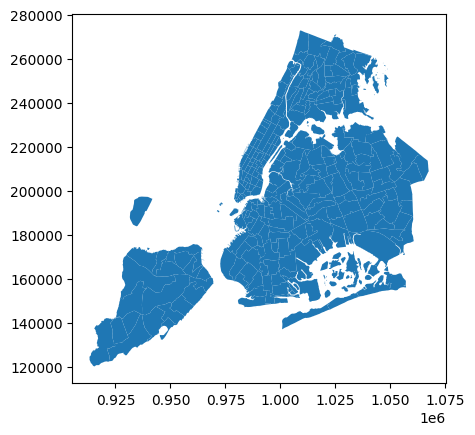

In [128]:
print(zones.info())
zones.plot()

Now, you have to merge the trip records and zones data using the location IDs.



**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [129]:
# Merge zones and trip records using locationID and PULocationID
pickup_df = df.merge(
    zones,
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)


**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [131]:
# Group data by location and calculate the number of trips
pickup_df = df.merge(
    zones,
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)
trip_counts = (
    pickup_df.groupby(
        ["LocationID", "zone", "borough"]
    )
    .size()
    .reset_index(name="trip_count")
    .sort_values(
        "trip_count",
        ascending=False
    )
)

trip_counts.head(10)

,LocationID,zone,borough,trip_count
124,132.0,JFK Airport,Queens,96615
228,237.0,Upper East Side South,Manhattan,86818
153,161.0,Midtown Center,Manhattan,85864
227,236.0,Upper East Side North,Manhattan,77464
154,162.0,Midtown East,Manhattan,65566
130,138.0,LaGuardia Airport,Queens,64117
177,186.0,Penn Station/Madison Sq West,Manhattan,63401
221,230.0,Times Sq/Theatre District,Manhattan,61236
134,142.0,Lincoln Square East,Manhattan,60814
162,170.0,Murray Hill,Manhattan,54436


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [133]:
# Merge trip counts back to the zones GeoDataFrame
trip_counts = (
    pickup_df.groupby("LocationID")
    .size()
    .reset_index(name="trip_count")
)

zones_trips = zones.merge(
    trip_counts,
    on="LocationID",
    how="left"
)

zones_trips["trip_count"] = (
    zones_trips["trip_count"]
    .fillna(0)
)


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

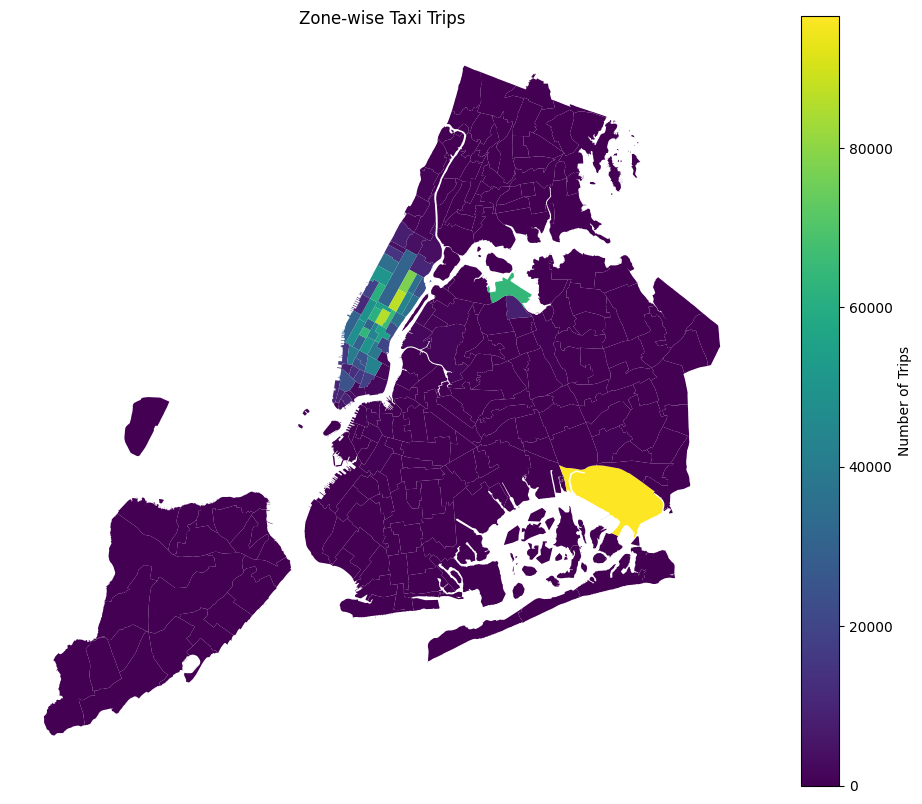

In [134]:
# Define figure and axis


# Plot the map and display it

fig, ax = plt.subplots(
    1, 1,
    figsize=(12, 10)
)

zones_trips.plot(
    column="trip_count",
    ax=ax,
    legend=True,
    legend_kwds={
        "label": "Number of Trips",
        "orientation": "vertical"
    }
)

ax.set_title("Zone-wise Taxi Trips")
ax.axis("off")

plt.show()

In [135]:
# can you try displaying the zones DF sorted by the number of trips?
zones_trips.sort_values(
    by="trip_count",
    ascending=False
)[
    [
        "LocationID",
        "zone",
        "borough",
        "trip_count"
    ]
]


,LocationID,zone,borough,trip_count
131,132,JFK Airport,Queens,96615.0
236,237,Upper East Side South,Manhattan,86818.0
160,161,Midtown Center,Manhattan,85864.0
235,236,Upper East Side North,Manhattan,77464.0
161,162,Midtown East,Manhattan,65566.0
...,...,...,...,...
104,103,Governor's Island/Ellis Island/Liberty Island,Manhattan,0.0
109,110,Great Kills Park,Staten Island,0.0
98,99,Freshkills Park,Staten Island,0.0
29,30,Broad Channel,Queens,0.0


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [146]:
# Find routes which have the slowest speeds at different times of the day

route_speed_df = (
    df.groupby(
        [
            "pulocationid",
            "dolocationid",
            "pickup_hour"
        ]
    )
    .agg(
        avg_distance=("trip_distance", "mean"),
        avg_duration=("trip_duration", "mean")
    )
    .reset_index()
)

route_speed_df["avg_speed"] = (
    route_speed_df["avg_distance"] /
    (route_speed_df["avg_duration"] / 60)
)

route_speed_df = (
    df.groupby(
        [
            "pulocationid",
            "dolocationid",
            "pickup_hour"
        ]
    )
    .agg(
        trip_count=("trip_distance", "size"),
        avg_distance=("trip_distance", "mean"),
        avg_duration=("trip_duration", "mean")
    )
    .reset_index()
)

route_speed_df["avg_speed"] = (
    route_speed_df["avg_distance"] /
    (route_speed_df["avg_duration"] / 60)
)


route_speed_df = route_speed_df[
    route_speed_df["trip_count"] >= 20
]

route_speed_df = route_speed_df[
    route_speed_df["pulocationid"] !=
    route_speed_df["dolocationid"]
]

slow_routes = (
    route_speed_df.sort_values(
        by="avg_speed"
    )
)

slow_routes.head(20)

zone_lookup = zones[
    ["LocationID", "zone"]
]

slow_routes = slow_routes.merge(
    zone_lookup,
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)

slow_routes.rename(
    columns={"zone": "pickup_zone"},
    inplace=True
)

slow_routes = slow_routes.merge(
    zone_lookup,
    left_on="dolocationid",
    right_on="LocationID",
    how="left"
)

slow_routes.rename(
    columns={"zone": "dropoff_zone"},
    inplace=True
)

slow_routes[
    [
        "pickup_zone",
        "dropoff_zone",
        "pickup_hour",
        "trip_count",
        "avg_speed"
    ]
].sort_values(
    "avg_speed"
).head(20)

,pickup_zone,dropoff_zone,pickup_hour,trip_count,avg_speed
0,Penn Station/Madison Sq West,Garment District,12,78,2.880604
1,Penn Station/Madison Sq West,Garment District,11,71,3.112156
2,Penn Station/Madison Sq West,Garment District,16,68,3.170803
3,Penn Station/Madison Sq West,Garment District,13,96,3.200294
4,Penn Station/Madison Sq West,Midtown South,12,81,3.250947
5,Penn Station/Madison Sq West,Garment District,18,64,3.307807
6,Penn Station/Madison Sq West,Times Sq/Theatre District,12,304,3.449070
7,Garment District,Clinton East,13,59,3.461748
8,Penn Station/Madison Sq West,Garment District,15,71,3.484140
9,Penn Station/Madison Sq West,Garment District,10,72,3.519637


How does identifying high-traffic, high-demand routes help us?

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

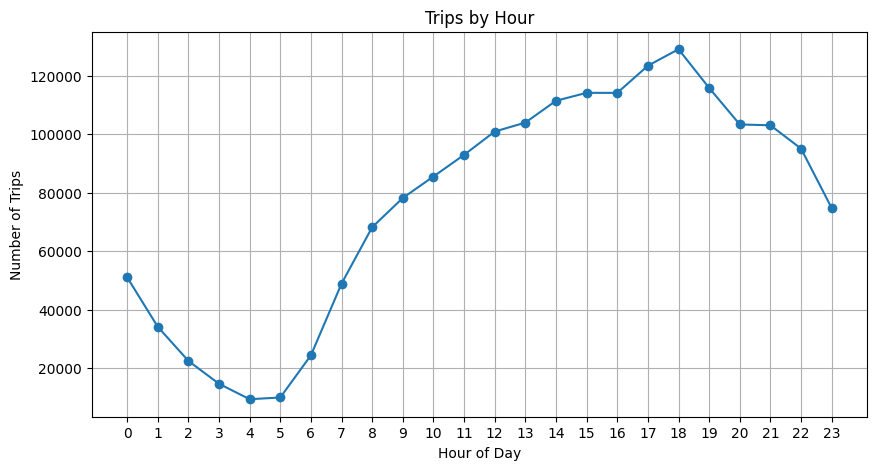

In [147]:
# Visualise the number of trips per hour and find the busiest hour
df["pickup_hour"] = (
    df["tpep_pickup_datetime"]
    .dt.hour
)
hourly_trips = (
    df.groupby("pickup_hour")
      .size()
      .reset_index(name="trip_count")
      .sort_values("pickup_hour")
)

hourly_trips

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_trips["pickup_hour"],
    hourly_trips["trip_count"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Trips by Hour")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [149]:
busiest_hour = hourly_trips.loc[
    hourly_trips["trip_count"].idxmax()
]

busiest_hour

,18
pickup_hour,18
trip_count,129036


Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [150]:
# Scale up the number of trips

# Fill in the value of your sampling fraction and use that to scale up the numbers
sample_fraction = 0.05

top_5_hours = (
    hourly_trips
    .sort_values("trip_count", ascending=False)
    .head(5)
    .copy()
)

top_5_hours["actual_trip_count"] = (
    top_5_hours["trip_count"] * 20
)

top_5_hours

,pickup_hour,trip_count,actual_trip_count
18,18,129036,2580720
17,17,123394,2467880
19,19,115809,2316180
15,15,114134,2282680
16,16,114108,2282160


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

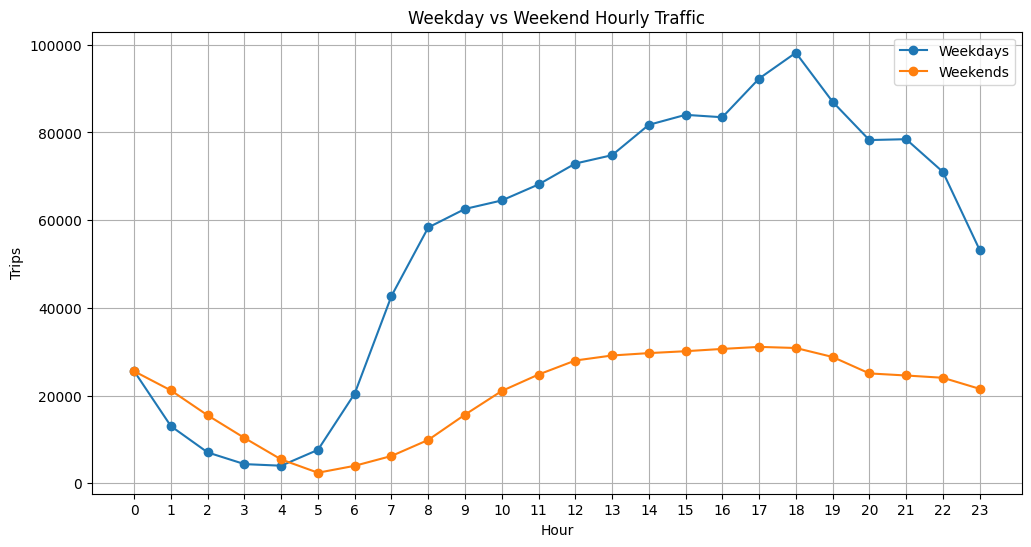

In [151]:
# Compare traffic trends for the week days and weekends
df["day_of_week"] = df["tpep_pickup_datetime"].dt.dayofweek
df["is_weekend"] = df["day_of_week"].isin([5, 6])

weekday_hourly = (
    df[~df["is_weekend"]]
    .groupby("pickup_hour")
    .size()
)

weekend_hourly = (
    df[df["is_weekend"]]
    .groupby("pickup_hour")
    .size()
)

plt.figure(figsize=(12, 6))

plt.plot(
    weekday_hourly.index,
    weekday_hourly.values,
    marker="o",
    label="Weekdays"
)

plt.plot(
    weekend_hourly.index,
    weekend_hourly.values,
    marker="o",
    label="Weekends"
)

plt.xlabel("Hour")
plt.ylabel("Trips")
plt.title("Weekday vs Weekend Hourly Traffic")
plt.xticks(range(24))
plt.legend()
plt.grid(True)

plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [153]:
# Find top 10 pickup and dropoff zones
top_pickup_zones = (
    df.groupby("pulocationid")
      .size()
      .reset_index(name="pickup_count")
      .sort_values(
          "pickup_count",
          ascending=False
      )
      .head(10)
)

top_pickup_zones = top_pickup_zones.merge(
    zones[["LocationID", "zone"]],
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)

top_pickup_zones[["zone", "pickup_count"]]




,zone,pickup_count
0,JFK Airport,96615
1,Upper East Side South,86818
2,Midtown Center,85864
3,Upper East Side North,77464
4,Midtown East,65566
5,LaGuardia Airport,64117
6,Penn Station/Madison Sq West,63401
7,Times Sq/Theatre District,61236
8,Lincoln Square East,60814
9,Murray Hill,54436


In [152]:
top_dropoff_zones = (
    df.groupby("dolocationid")
      .size()
      .reset_index(name="dropoff_count")
      .sort_values(
          "dropoff_count",
          ascending=False
      )
      .head(10)
)

top_dropoff_zones = top_dropoff_zones.merge(
    zones[["LocationID", "zone"]],
    left_on="dolocationid",
    right_on="LocationID",
    how="left"
)

top_dropoff_zones[["zone", "dropoff_count"]]

,zone,dropoff_count
0,Upper East Side North,81200
1,Upper East Side South,77502
2,Midtown Center,71592
3,Times Sq/Theatre District,56331
4,Murray Hill,54276
5,Midtown East,52225
6,Lincoln Square East,51448
7,Upper West Side South,51214
8,Lenox Hill West,48418
9,East Chelsea,46301


In [154]:
top_pickup_ids = top_pickup_zones["pulocationid"]

pickup_hourly = (
    df[df["pulocationid"].isin(top_pickup_ids)]
    .groupby(
        ["pulocationid", "pickup_hour"]
    )
    .size()
    .reset_index(name="trip_count")
)

pickup_hourly = pickup_hourly.merge(
    zones[["LocationID", "zone"]],
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)

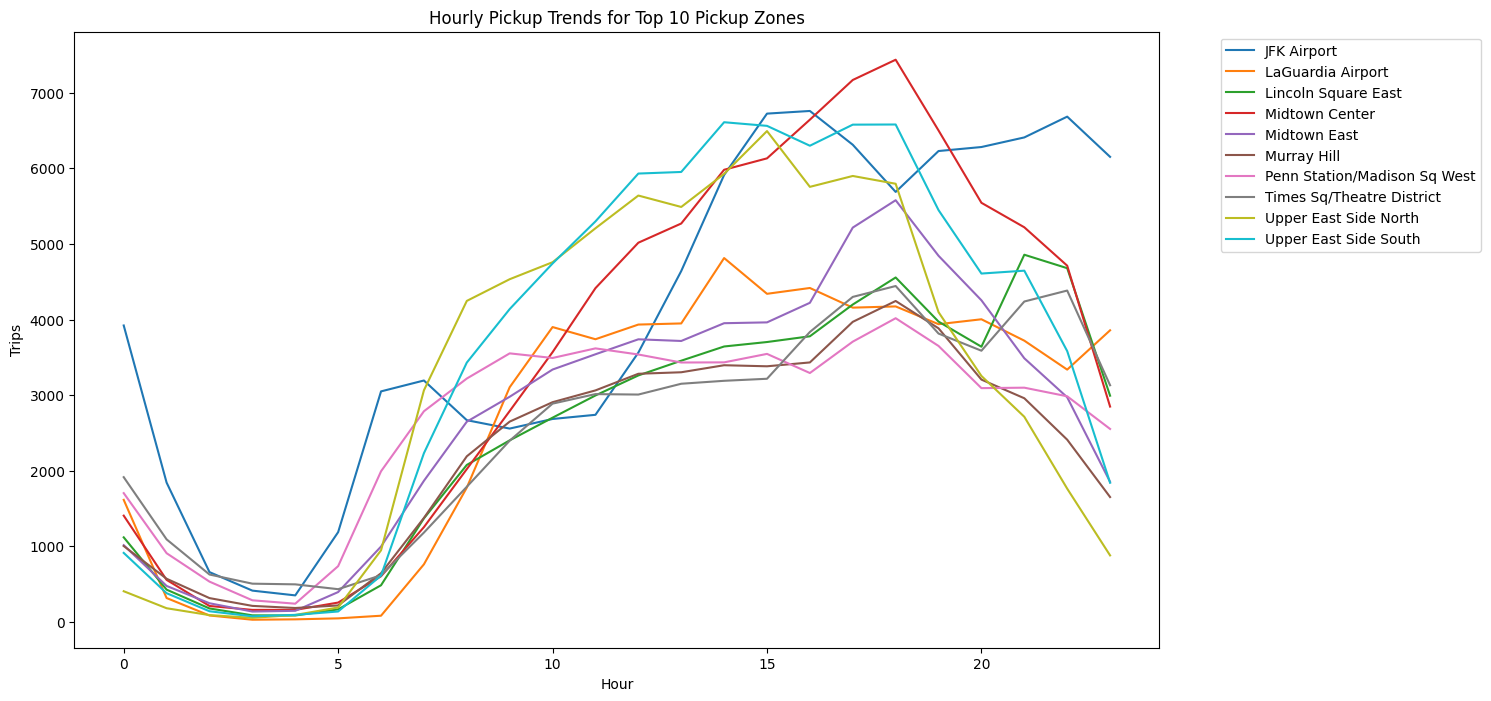

In [155]:

plt.figure(figsize=(14, 8))

for zone in pickup_hourly["zone"].unique():
    temp = pickup_hourly[
        pickup_hourly["zone"] == zone
    ]

    plt.plot(
        temp["pickup_hour"],
        temp["trip_count"],
        label=zone
    )

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Hour")
plt.ylabel("Trips")
plt.title("Hourly Pickup Trends for Top 10 Pickup Zones")

plt.show()

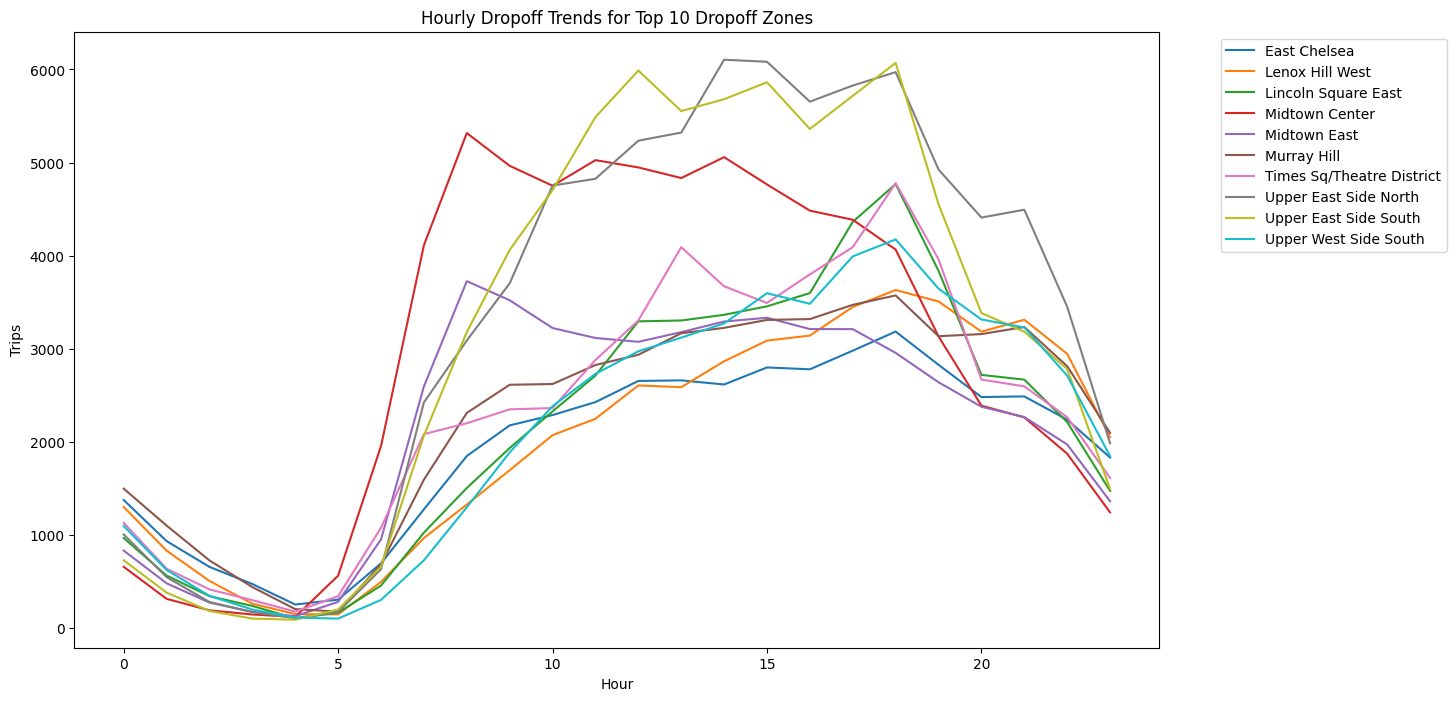

In [156]:
top_dropoff_ids = top_dropoff_zones["dolocationid"]

dropoff_hourly = (
    df[df["dolocationid"].isin(top_dropoff_ids)]
    .groupby(
        ["dolocationid", "pickup_hour"]
    )
    .size()
    .reset_index(name="trip_count")
)

dropoff_hourly = dropoff_hourly.merge(
    zones[["LocationID", "zone"]],
    left_on="dolocationid",
    right_on="LocationID",
    how="left"
)

plt.figure(figsize=(14, 8))

for zone in dropoff_hourly["zone"].unique():
    temp = dropoff_hourly[
        dropoff_hourly["zone"] == zone
    ]

    plt.plot(
        temp["pickup_hour"],
        temp["trip_count"],
        label=zone
    )

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Hour")
plt.ylabel("Trips")
plt.title("Hourly Dropoff Trends for Top 10 Dropoff Zones")

plt.show()

**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [159]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

pickup_counts = (
    df.groupby("pulocationid")
      .size()
      .reset_index(name="pickup_count")
)

dropoff_counts = (
    df.groupby("dolocationid")
      .size()
      .reset_index(name="dropoff_count")
)

zone_flow = pickup_counts.merge(
    dropoff_counts,
    left_on="pulocationid",
    right_on="dolocationid",
    how="outer"
)

zone_flow["LocationID"] = (
    zone_flow["pulocationid"]
    .fillna(zone_flow["dolocationid"])
)

zone_flow["pickup_count"] = (
    zone_flow["pickup_count"]
    .fillna(0)
)

zone_flow["dropoff_count"] = (
    zone_flow["dropoff_count"]
    .fillna(0)
)

zone_flow["pickup_dropoff_ratio"] = (
    zone_flow["pickup_count"]
    / zone_flow["dropoff_count"]
)

zone_flow = zone_flow.merge(
    zones[["LocationID", "zone"]],
    on="LocationID",
    how="left"
)

top_10_ratio = (
    zone_flow[
        zone_flow["dropoff_count"] > 0
    ]
    .sort_values(
        "pickup_dropoff_ratio",
        ascending=False
    )
    .head(10)
)

top_10_ratio[
    ["zone",
     "pickup_count",
     "dropoff_count",
     "pickup_dropoff_ratio"]
]

,zone,pickup_count,dropoff_count,pickup_dropoff_ratio
70,East Elmhurst,8326.0,1001.0,8.317682
128,JFK Airport,96615.0,20926.0,4.616984
134,LaGuardia Airport,64117.0,22216.0,2.886073
182,Penn Station/Madison Sq West,63401.0,40083.0,1.581743
42,Central Park,30711.0,22335.0,1.375017
110,Greenwich Village South,24068.0,17522.0,1.373587
245,West Village,40350.0,30440.0,1.325558
158,Midtown East,65566.0,52225.0,1.255452
157,Midtown Center,85864.0,71592.0,1.199352
100,Garment District,30175.0,25320.0,1.191746


In [160]:
bottom_10_ratio = (
    zone_flow[
        zone_flow["dropoff_count"] > 0
    ]
    .sort_values(
        "pickup_dropoff_ratio"
    )
    .head(10)
)

bottom_10_ratio[
    ["zone",
     "pickup_count",
     "dropoff_count",
     "pickup_dropoff_ratio"]
]

,zone,pickup_count,dropoff_count,pickup_dropoff_ratio
29,Broad Channel,0.0,18.0,0.000000
241,West Brighton,0.0,30.0,0.000000
172,Oakwood,0.0,12.0,0.000000
99,Freshkills Park,0.0,3.0,0.000000
26,Breezy Point/Fort Tilden/Riis Beach,1.0,39.0,0.025641
217,Stapleton,1.0,34.0,0.029412
253,Windsor Terrace,28.0,757.0,0.036988
0,Newark Airport,213.0,5310.0,0.040113
111,Grymes Hill/Clifton,1.0,23.0,0.043478
194,Ridgewood,51.0,984.0,0.051829


**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [163]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

night_df = df[
    df["pickup_hour"].isin([23, 0, 1, 2, 3, 4, 5])
]

night_pickups = (
    night_df.groupby("pulocationid")
            .size()
            .reset_index(name="pickup_count")
            .sort_values(
                "pickup_count",
                ascending=False
            )
            .head(10)
)

night_pickups = night_pickups.merge(
    zones[["LocationID", "zone"]],
    left_on="pulocationid",
    right_on="LocationID",
    how="left"
)

night_pickups[
    ["zone", "pickup_count"]
]


,zone,pickup_count
0,East Village,15526
1,JFK Airport,14523
2,West Village,12450
3,Clinton East,10452
4,Lower East Side,9602
5,Greenwich Village South,8731
6,Times Sq/Theatre District,8194
7,Penn Station/Madison Sq West,6957
8,Midtown South,6129
9,East Chelsea,6038


In [164]:

night_dropoffs = (
    night_df.groupby("dolocationid")
            .size()
            .reset_index(name="dropoff_count")
            .sort_values(
                "dropoff_count",
                ascending=False
            )
            .head(10)
)

night_dropoffs = night_dropoffs.merge(
    zones[["LocationID", "zone"]],
    left_on="dolocationid",
    right_on="LocationID",
    how="left"
)

night_dropoffs[
    ["zone", "dropoff_count"]
]

,zone,dropoff_count
0,East Village,8306
1,Clinton East,6865
2,Murray Hill,6260
3,East Chelsea,5850
4,Gramercy,5752
5,Lenox Hill West,5266
6,Yorkville West,4967
7,West Village,4939
8,Times Sq/Theatre District,4635
9,Lower East Side,4375


Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [165]:
# Filter for night hours (11 PM to 5 AM)
night_hours = [23, 0, 1, 2, 3, 4, 5]
night_df = df[
    df["pickup_hour"].isin(night_hours)
]

day_df = df[
    ~df["pickup_hour"].isin(night_hours)
]
night_revenue = night_df["total_amount"].sum()
day_revenue = day_df["total_amount"].sum()

print(f"Night Revenue: ${night_revenue:,.2f}")
print(f"Day Revenue: ${day_revenue:,.2f}")

Night Revenue: $6,383,248.48
Day Revenue: $46,396,325.68


In [166]:
total_revenue = df["total_amount"].sum()

night_pct = (
    night_revenue / total_revenue
) * 100

day_pct = (
    day_revenue / total_revenue
) * 100

print(f"Night Revenue %: {night_pct:.2f}%")
print(f"Day Revenue %: {day_pct:.2f}%")

Night Revenue %: 12.09%
Day Revenue %: 87.91%


In [167]:
revenue_summary = pd.DataFrame({
    "Period": ["Day", "Night"],
    "Revenue": [
        day_revenue,
        night_revenue
    ]
})

revenue_summary["Revenue %"] = (
    revenue_summary["Revenue"]
    / revenue_summary["Revenue"].sum()
    * 100
)

revenue_summary

,Period,Revenue,Revenue %
0,Day,46396325.68,87.905836
1,Night,6383248.48,12.094164


##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

In [168]:
# Analyse the fare per mile per passenger for different passenger counts

fare_df = df[
    df["trip_distance"] > 0
].copy()

fare_df["fare_per_mile_per_passenger"] = (
    fare_df["fare_amount"]
    / (
        fare_df["trip_distance"]
        * fare_df["passenger_count"]
    )
)

fare_per_passenger = (
    fare_df.groupby("passenger_count")[
        "fare_per_mile_per_passenger"
    ]
    .mean()
    .reset_index()
)

fare_per_passenger

,passenger_count,fare_per_mile_per_passenger
0,1.0,10.852677
1,2.0,6.429067
2,3.0,3.908700
3,4.0,4.365880
4,5.0,1.710766
5,6.0,1.351586


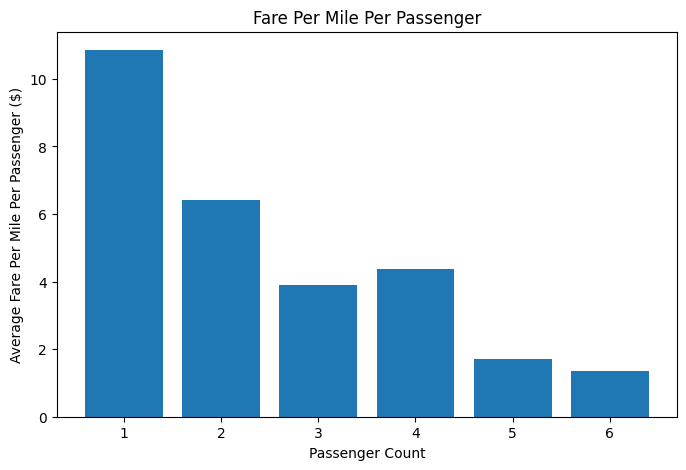

In [169]:
plt.figure(figsize=(8, 5))

plt.bar(
    fare_per_passenger["passenger_count"],
    fare_per_passenger["fare_per_mile_per_passenger"]
)

plt.xlabel("Passenger Count")
plt.ylabel("Average Fare Per Mile Per Passenger ($)")
plt.title("Fare Per Mile Per Passenger")

plt.show()

**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

In [170]:
# Compare the average fare per mile for different days and for different times of the day
fare_df = df[
    df["trip_distance"] > 0
].copy()

fare_df["fare_per_mile"] = (
    fare_df["fare_amount"]
    / fare_df["trip_distance"]
)
fare_df["day_name"] = (
    fare_df["tpep_pickup_datetime"]
    .dt.day_name()
)
hourly_fare = (
    fare_df.groupby("pickup_hour")
           ["fare_per_mile"]
           .mean()
           .reset_index()
)

hourly_fare

,pickup_hour,fare_per_mile
0,0,10.528887
1,1,11.149668
2,2,9.944955
3,3,10.874598
4,4,14.008751
5,5,14.247068
6,6,11.205953
7,7,10.285323
8,8,10.366715
9,9,10.393687


<Axes: xlabel='pickup_hour'>

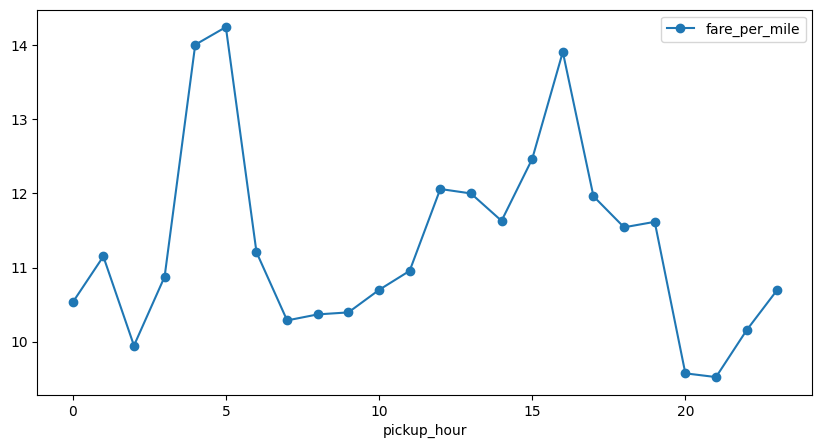

In [171]:
hourly_fare.plot(
    x="pickup_hour",
    y="fare_per_mile",
    kind="line",
    marker="o",
    figsize=(10,5)
)

In [172]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_fare = (
    fare_df.groupby("day_name")
           ["fare_per_mile"]
           .mean()
           .reindex(day_order)
           .reset_index()
)

daily_fare



,day_name,fare_per_mile
0,Monday,10.983431
1,Tuesday,11.365994
2,Wednesday,11.112514
3,Thursday,11.261550
4,Friday,10.891207
5,Saturday,10.916722
6,Sunday,12.533329


<Axes: xlabel='day_name'>

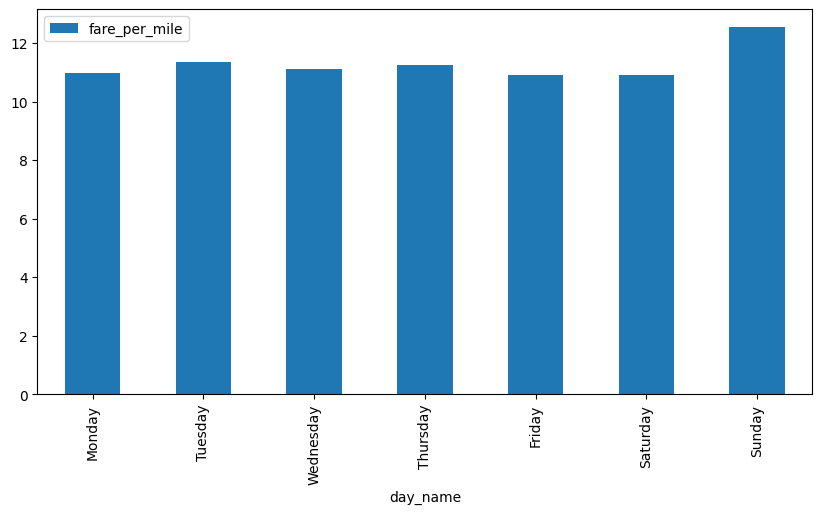

In [173]:
daily_fare.plot(
    x="day_name",
    y="fare_per_mile",
    kind="bar",
    figsize=(10,5)
)

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

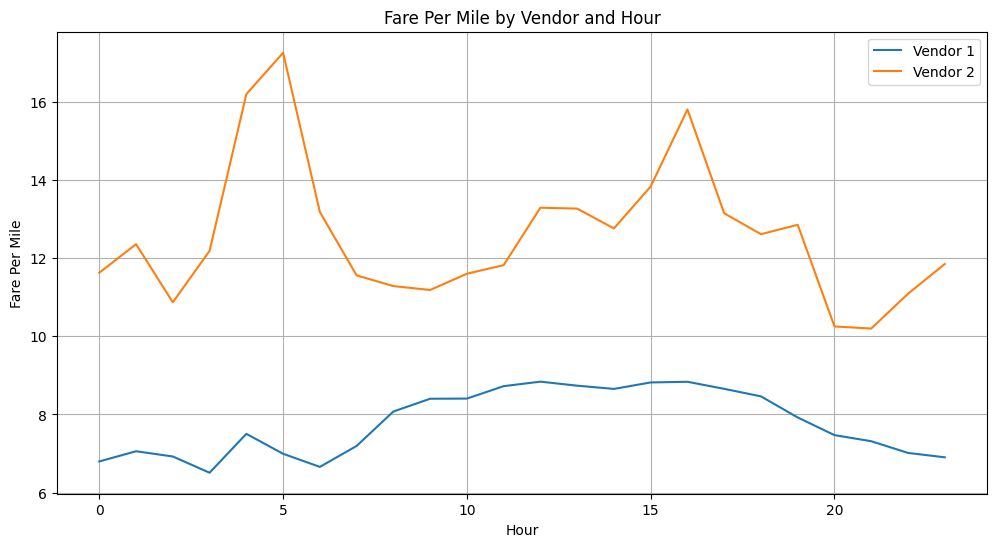

In [174]:
# Compare fare per mile for different vendors

vendor_hourly = (
    fare_df.groupby(
        ["vendorid", "pickup_hour"]
    )["fare_per_mile"]
     .mean()
     .reset_index()
)

plt.figure(figsize=(12,6))

for vendor in vendor_hourly["vendorid"].unique():
    temp = vendor_hourly[
        vendor_hourly["vendorid"] == vendor
    ]

    plt.plot(
        temp["pickup_hour"],
        temp["fare_per_mile"],
        label=f"Vendor {vendor}"
    )

plt.legend()
plt.xlabel("Hour")
plt.ylabel("Fare Per Mile")
plt.title("Fare Per Mile by Vendor and Hour")
plt.grid(True)

plt.show()

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


In [179]:
df.columns

Index(['vendorid', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'ratecodeid', 'store_and_fwd_flag',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'airport_fee', 'pickup_hour',
       'pickup_month', 'quarter', 'trip_duration', 'day_of_week',
       'is_weekend'],
      dtype='object')

In [180]:
# Defining distance tiers
fare_df["distance_tier"] = pd.cut(
    fare_df["trip_distance"],
    bins=[0, 2, 5, float("inf")],
    labels=["0-2 Miles", "2-5 Miles", "5+ Miles"]
)

fare_df["fare_per_mile"] = (
    fare_df["fare_amount"]
    / fare_df["trip_distance"]
)


tier_vendor = (
    fare_df.groupby(
        ["distance_tier", "vendorid"]
    )["fare_per_mile"]
    .mean()
    .reset_index()
)

tier_vendor



,distance_tier,vendorid,fare_per_mile
0,0-2 Miles,1,9.926140
1,0-2 Miles,2,17.906218
2,2-5 Miles,1,6.379783
3,2-5 Miles,2,6.548877
4,5+ Miles,1,4.422048
5,5+ Miles,2,4.502141


In [183]:
tier_vendor_pivot = tier_vendor.pivot(
    index="distance_tier",
    columns="vendorid",
    values="fare_per_mile"
)

tier_vendor_pivot

vendorid,1,2
distance_tier,,
0-2 Miles,9.926140,17.906218
2-5 Miles,6.379783,6.548877
5+ Miles,4.422048,4.502141


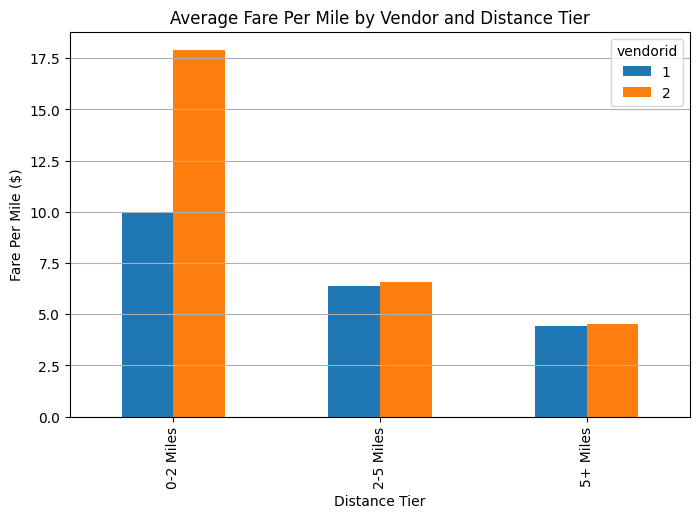

In [184]:
tier_vendor_pivot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Fare Per Mile by Vendor and Distance Tier")
plt.ylabel("Fare Per Mile ($)")
plt.xlabel("Distance Tier")
plt.grid(axis="y")

plt.show()

##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

In [185]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
tip_df = df[
    df["fare_amount"] > 0
].copy()

tip_df["tip_percentage"] = (
    tip_df["tip_amount"]
    / tip_df["fare_amount"]
) * 100
tip_df["distance_tier"] = pd.cut(
    tip_df["trip_distance"],
    bins=[0, 2, 5, float("inf")],
    labels=["0-2 Miles", "2-5 Miles", "5+ Miles"]
)

distance_tips = (
    tip_df.groupby("distance_tier")
          ["tip_percentage"]
          .mean()
          .reset_index()
)

distance_tips

,distance_tier,tip_percentage
0,0-2 Miles,22.425787
1,2-5 Miles,18.773973
2,5+ Miles,17.651672


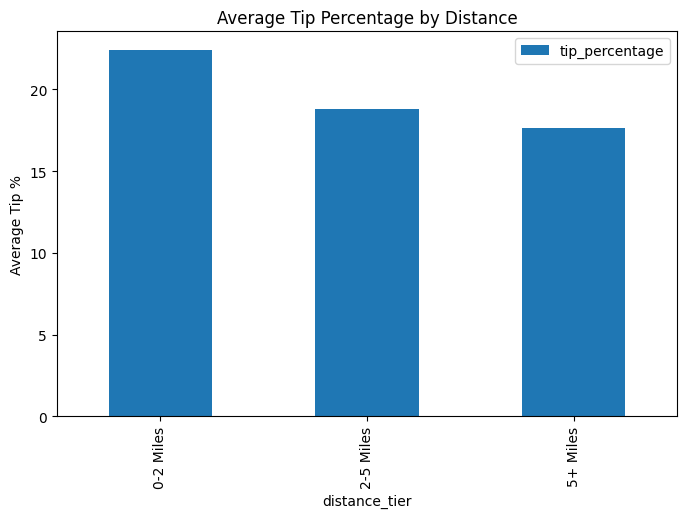

In [186]:
distance_tips.plot(
    x="distance_tier",
    y="tip_percentage",
    kind="bar",
    figsize=(8,5)
)

plt.ylabel("Average Tip %")
plt.title("Average Tip Percentage by Distance")
plt.show()

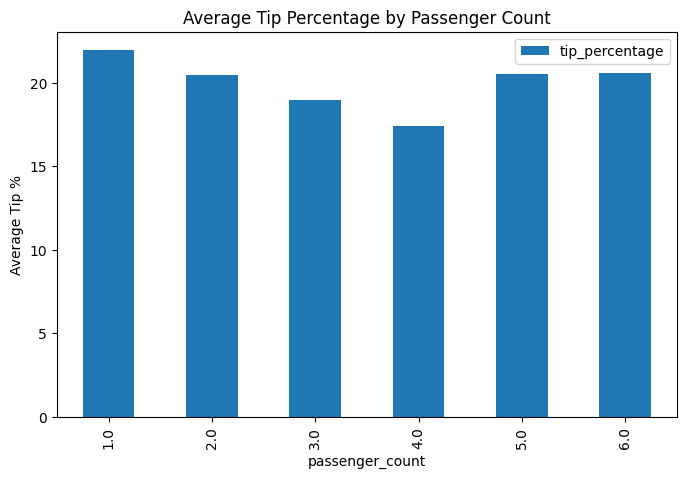

In [188]:
passenger_tips = (
    tip_df.groupby("passenger_count")
          ["tip_percentage"]
          .mean()
          .reset_index()
)

passenger_tips

passenger_tips.plot(
    x="passenger_count",
    y="tip_percentage",
    kind="bar",
    figsize=(8,5)
)

plt.ylabel("Average Tip %")
plt.title("Average Tip Percentage by Passenger Count")
plt.show()

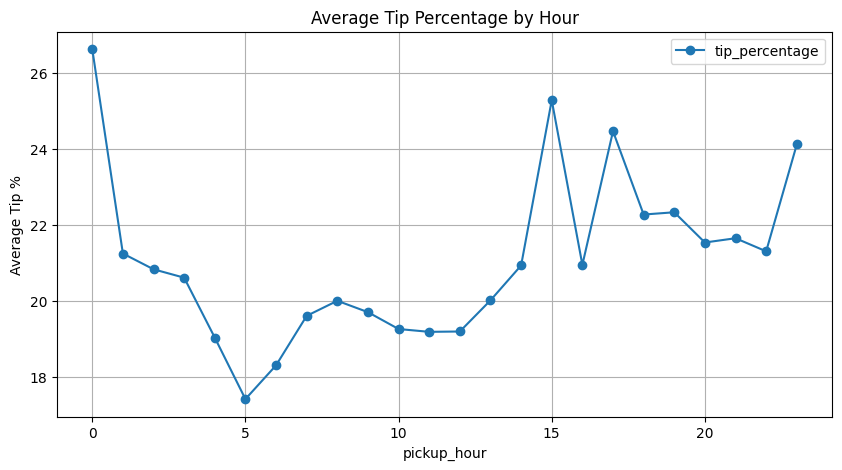

In [189]:
hourly_tips = (
    tip_df.groupby("pickup_hour")
          ["tip_percentage"]
          .mean()
          .reset_index()
)

hourly_tips
hourly_tips.plot(
    x="pickup_hour",
    y="tip_percentage",
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.ylabel("Average Tip %")
plt.title("Average Tip Percentage by Hour")
plt.grid(True)

plt.show()


In [190]:
print("Lowest tip by distance")
print(distance_tips.sort_values("tip_percentage"))

print("\nLowest tip by passenger count")
print(passenger_tips.sort_values("tip_percentage"))

print("\nLowest tip hours")
print(hourly_tips.sort_values("tip_percentage").head(10))

Lowest tip by distance
  distance_tier  tip_percentage
2      5+ Miles       17.651672
1     2-5 Miles       18.773973
0     0-2 Miles       22.425787

Lowest tip by passenger count
   passenger_count  tip_percentage
3              4.0       17.391087
2              3.0       18.977522
1              2.0       20.467310
4              5.0       20.562970
5              6.0       20.624274
0              1.0       21.970294

Lowest tip hours
    pickup_hour  tip_percentage
5             5       17.405403
6             6       18.294554
4             4       19.024682
11           11       19.177052
12           12       19.185993
10           10       19.251120
7             7       19.597882
9             9       19.695457
8             8       19.994583
13           13       20.006832


Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [ ]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%



**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

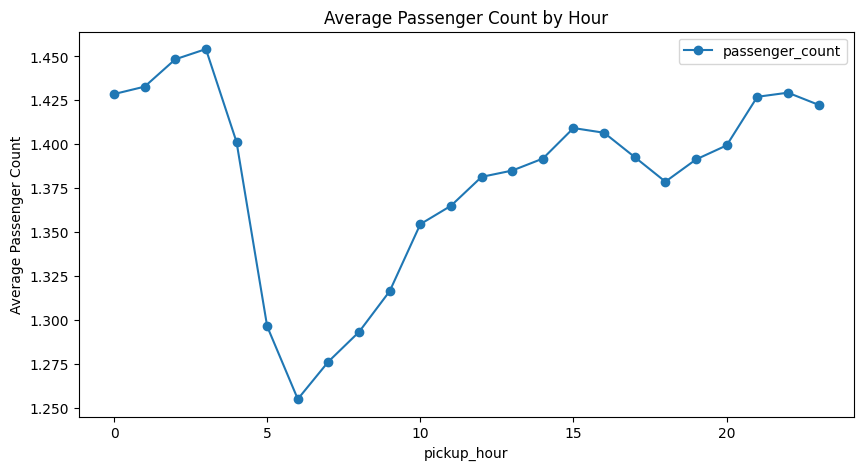

In [191]:
# See how passenger count varies across hours and days

hourly_passengers = (
    df.groupby("pickup_hour")["passenger_count"]
      .mean()
      .reset_index()
)

hourly_passengers.plot(
    x="pickup_hour",
    y="passenger_count",
    marker="o",
    figsize=(10, 5),
    title="Average Passenger Count by Hour"
)

plt.ylabel("Average Passenger Count")
plt.show()




**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [ ]:
# How does passenger count vary across zones



In [ ]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.



Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

In [193]:
# How often is each surcharge applied?
[
    "extra",
    "mta_tax",
    "improvement_surcharge",
    "congestion_surcharge",
    "airport_fee"
]
df[
    [
        "extra",
        "mta_tax",
        "improvement_surcharge",
        "congestion_surcharge",
        "airport_fee"
    ]
].describe()

,extra,mta_tax,improvement_surcharge,congestion_surcharge,airport_fee
count,1.829046e+06,1.829046e+06,1.829046e+06,1.829046e+06,1.829046e+06
mean,1.638555e+00,4.953917e-01,9.993787e-01,2.308135e+00,1.428676e-01
std,1.836262e+00,4.806556e-02,2.297787e-02,6.654703e-01,4.647831e-01
min,-2.500000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,5.000000e-01,1.000000e+00,2.500000e+00,0.000000e+00
50%,1.000000e+00,5.000000e-01,1.000000e+00,2.500000e+00,0.000000e+00
75%,2.500000e+00,5.000000e-01,1.000000e+00,2.500000e+00,0.000000e+00
max,1.425000e+01,4.000000e+00,1.000000e+00,2.500000e+00,1.750000e+00


In [194]:
surcharge_frequency = pd.DataFrame({
    "extra": (df["extra"] > 0).sum(),
    "mta_tax": (df["mta_tax"] > 0).sum(),
    "improvement_surcharge": (df["improvement_surcharge"] > 0).sum(),
    "congestion_surcharge": (df["congestion_surcharge"] > 0).sum(),
    "airport_fee": (df["airport_fee"] > 0).sum()
}, index=["count"]).T

surcharge_frequency.columns = ["trip_count"]

surcharge_frequency["percentage"] = (
    surcharge_frequency["trip_count"]
    / len(df)
    * 100
)

surcharge_frequency.sort_values(
    "percentage",
    ascending=False
)

,trip_count,percentage
improvement_surcharge,1828476,99.968836
mta_tax,1812154,99.076458
congestion_surcharge,1688674,92.325398
extra,1133039,61.946993
airport_fee,160679,8.784853


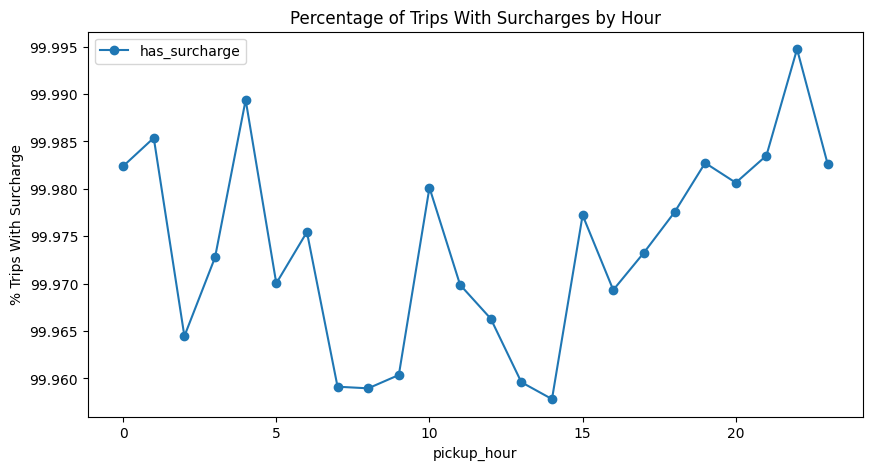

In [196]:
df["has_surcharge"] = (
    (df["extra"] > 0)
    | (df["mta_tax"] > 0)
    | (df["improvement_surcharge"] > 0)
    | (df["congestion_surcharge"] > 0)
    | (df["airport_fee"] > 0)
)

hourly_surcharge = (
    df.groupby("pickup_hour")["has_surcharge"]
      .mean()
      .mul(100)
      .reset_index()
)

hourly_surcharge.plot(
    x="pickup_hour",
    y="has_surcharge",
    marker="o",
    figsize=(10,5),
    title="Percentage of Trips With Surcharges by Hour"
)

plt.ylabel("% Trips With Surcharge")
plt.show()

In [198]:
save_csv(df)

## **4** Conclusion
<font color = red>[15 marks]</font> <br>



### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

## Conclusion is:

### Demand Patterns
- Taxi demand varies significantly throughout the day.
- Pickup activity is lowest during early morning hours (around 4–5 AM).
- Demand increases sharply after 6 AM and remains high throughout the afternoon and evening.
- The busiest hour is around 6 PM, indicating strong evening commuting. Office finish hours.

### Revenue
- Daytime trips generate approx. 88% of total revenue and night trips contribute only about 12%.
- More number of trips lead to more amount of revenue.

### Trip characterstics
- Fare amount and trip duration are strogly correlated.
- Tip amount shows a medium positive correlation with trip distance.

### Passenger behaviours
- Most taxi rides are small group, 1 or 2 passengers.
- Passenger count doesn't impact fare amount.

### Geo analysis
- Airport zones are the most active pickup locations

### Vendor analysis
- Vendor 2 consistently charge higher fare then vendor 1 for short trips


**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

- Increase driver availability during morning and evening hours
- Schedule driver shifts that syncs with peak demand periods
- Use models to forecast peak demand position and position taxis there

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

- Propose time based pricing for peak time.
- Adjust pricing in high demand zones.
- Vendor 1 can selectively increase rates.